# PortfolioPilot - Milestone 3: cleaning, EDA, dimension reduction, feature set



**Run the cells in order, top to bottom.** Each cell uses variables made by the cells before it.
After a kernel restart, start again from cell 1.

Rule for M3: the test sets are created in Step 3 and then never explored. Every statistic, cap,
table and figure uses **training data only**.

In [3]:
%pip install numpy pandas scipy scikit-learn matplotlib yfinance

## Step 1 - Setting up

In [10]:
from google.colab import drive
drive.mount("/content/drive")          # a pop-up asks you to allow access: click Allow

import os
os.chdir("/content/drive/MyDrive/Portfolio_pilot/data/raw")
print("Working in:", os.getcwd())
print("Files here:", os.listdir())

from pathlib import Path
SCF_FILE = Path("SCFP2025.csv")
OUT_DIR  = Path("outputs")


SEED = 7275

# SCF column names in the summary extract (check against the SCF codebook)
COLS = {
    "household_id": "YY1", "record_id": "Y1", "weight": "WGT", "age": "AGE",
    "income": "INCOME", "networth": "NETWORTH", "liq": "LIQ", "debt": "DEBT",
    "equity": "EQUITY", "fin": "FIN", "yes_risk": "YESFINRISK", "no_risk": "NOFINRISK",
}
IMPLICATE = 1
SPLIT = {"train": 0.70, "val": 0.15, "test": 0.15}
CAP_QUANTILE = 0.99            # caps for ratio features, from training data

K_RANGE = [2, 3, 4, 5, 6]
CLUSTER_METHOD = "kmeans"      # "kmeans" or "gmm"
CHOSEN_K = None                # None = automatic (best silhouette); or set a number after Step 9
MIN_CLUSTER_SHARE = 0.05
N_BOOTSTRAP = 20               # use 3 for a quick test, 20 for final results
PCA_THRESHOLD = 0.80

TICKERS = ["SPY", "VEA", "VWO", "AGG", "TLT", "TIP", "VNQ", "GLD", "DBC"]
ETF_START, ETF_END = "2016-01-01", "2026-01-01"   # end is exclusive: data through 2025-12-31
ETF_TRAIN_END, ETF_VAL_END = "2021-12-31", "2023-12-31"
ETF_FILE = OUT_DIR / "raw" / "etf_prices_raw.csv"

FIG_DIR, TAB_DIR, DATA_DIR = OUT_DIR / "figures", OUT_DIR / "tables", OUT_DIR / "processed"
for d in [FIG_DIR, TAB_DIR, DATA_DIR, ETF_FILE.parent]:
    d.mkdir(parents=True, exist_ok=True)

print("SCF file found:", SCF_FILE.exists())
print("Outputs go to:", OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in: /content/drive/MyDrive/Portfolio_pilot/data/raw
Files here: ['SCFP2025.csv', 'PortfolioPilot_ETF_Prices.csv', 'outputs']
SCF file found: True
Outputs go to: outputs


## Step 2 - Import and helpers

In [13]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
np.random.seed(SEED)

NUMBERS = {}   # every count quoted in the report is stored here and saved in the last step
def note(section, key, value):
    NUMBERS.setdefault(section, {})[key] = value

def to_plain(v):
    """Make numpy values JSON-friendly."""
    if isinstance(v, dict):
        return {str(k): to_plain(x) for k, x in v.items()}
    if isinstance(v, (list, tuple)):
        return [to_plain(x) for x in v]
    if isinstance(v, np.integer):
        return int(v)
    if isinstance(v, (np.floating, float)):
        return round(float(v), 6)
    return v

def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def weighted_resample(df, seed):
    """Draw households with probability proportional to the survey weight."""
    rng = np.random.default_rng(seed)
    p = df["weight"].to_numpy(float)
    return df.iloc[rng.choice(len(df), size=len(df), replace=True, p=p / p.sum())]

def weighted_median(x, w):
    o = np.argsort(np.asarray(x))
    x, w = np.asarray(x, float)[o], np.asarray(w, float)[o]
    c = np.cumsum(w)
    return float(x[np.searchsorted(c, 0.5 * c[-1])])

print("Ready")

Ready


## Step 3 - Load the SCF and check its structure

In [14]:
raw = pd.read_csv(SCF_FILE, low_memory=False)
raw.columns = [c.upper() for c in raw.columns]
note("raw", "rows", len(raw))
note("raw", "columns", raw.shape[1])

missing_cols = [c for c in COLS.values() if c not in raw.columns]
assert not missing_cols, f"Columns not in the file: {missing_cols}. Fix COLS in Step 1."

full = raw[list(COLS.values())].copy()
full.columns = list(COLS.keys())
full["implicate"] = (full["record_id"] % 10).astype(int)    # Y1 = YY1*10 + implicate
note("raw", "households", full["household_id"].nunique())
note("raw", "implicates", sorted(full["implicate"].unique().tolist()))
del raw

print(NUMBERS["raw"])
full.head()

{'rows': 21800, 'columns': 362, 'households': 4360, 'implicates': [1, 2, 3, 4, 5]}


,household_id,record_id,weight,age,income,networth,liq,debt,equity,fin,yes_risk,no_risk,implicate
0,1,11,1241.701712,39,317351.35135,2434270.0,80300,250000.0,120150.0,215300,0,0,1
1,1,12,1247.038677,39,317351.35135,2208400.0,80300,250000.0,113800.0,229300,0,0,2
2,1,13,1234.428835,39,317351.35135,2128300.0,80300,250000.0,75300.0,209300,0,0,3
3,1,14,1267.530314,39,317351.35135,1742300.0,80300,250000.0,72800.0,212300,0,0,4
4,1,15,911.408367,39,317351.35135,1517300.0,80300,250000.0,73600.0,228300,0,0,5


## Step 4 - Cleaning: duplicates, missing values, impossible values

In [15]:
note("duplicates", "exact_duplicate_rows", int(full.duplicated().sum()))
note("duplicates", "duplicate_record_ids", int(full["record_id"].duplicated().sum()))
full = full.drop_duplicates(subset="record_id")

hh = full[full["implicate"] == IMPLICATE].copy()           # one row per household
note("implicate_1", "rows", len(hh))

na = hh.isna().sum()
note("missing", "by_column", na[na > 0].to_dict())
note("missing", "total", int(na.sum()))

checks = {
    "age_under_18_or_over_100": (hh["age"] < 18) | (hh["age"] > 100),
    "weight_not_positive": hh["weight"] <= 0,
    "liq_negative": hh["liq"] < 0,
    "debt_negative": hh["debt"] < 0,
    "equity_negative": hh["equity"] < 0,
    "fin_negative": hh["fin"] < 0,
    "equity_more_than_fin": hh["equity"] > hh["fin"] + 1,
    "liq_more_than_fin": hh["liq"] > hh["fin"] + 1,
    "both_risk_flags_1": (hh["yes_risk"] == 1) & (hh["no_risk"] == 1),
}
for name, mask in checks.items():
    note("errors", name, int(mask.sum()))
bad = checks["age_under_18_or_over_100"] | checks["weight_not_positive"] | checks["both_risk_flags_1"]
note("errors", "rows_dropped", int(bad.sum()))
hh = hh[~bad].reset_index(drop=True)

# Real values that need special handling later (not errors)
for name, mask in {"income_zero": hh["income"] == 0, "income_negative": hh["income"] < 0,
                   "networth_negative": hh["networth"] < 0, "fin_zero": hh["fin"] == 0,
                   "debt_zero": hh["debt"] == 0}.items():
    note("genuine", name, int(mask.sum()))

# Risk willingness: 0 = no risk, 1 = average, 2 = above-average / substantial
hh["risk_willingness"] = np.select([hh["no_risk"] == 1, hh["yes_risk"] == 1], [0, 2], default=1)
hh["age_band"] = pd.cut(hh["age"], [0, 34, 44, 54, 64, 74, 200],
                        labels=["<35", "35-44", "45-54", "55-64", "65-74", "75+"]).astype(str)
note("implicate_1", "rows_after_cleaning", len(hh))

for s in ["duplicates", "implicate_1", "missing", "errors", "genuine"]:
    print(s, NUMBERS[s])

duplicates {'exact_duplicate_rows': 0, 'duplicate_record_ids': 0}
implicate_1 {'rows': 4360, 'rows_after_cleaning': 4360}
missing {'by_column': {}, 'total': 0}
errors {'age_under_18_or_over_100': 0, 'weight_not_positive': 0, 'liq_negative': 0, 'debt_negative': 0, 'equity_negative': 0, 'fin_negative': 0, 'equity_more_than_fin': 0, 'liq_more_than_fin': 0, 'both_risk_flags_1': 0, 'rows_dropped': 0}
genuine {'income_zero': 23, 'income_negative': 0, 'networth_negative': 330, 'fin_zero': 53, 'debt_zero': 1115}


## Step 5 - Split train / validation / test (before any exploration)
Stratified on age band x risk willingness. Split by household, so implicates 2-5 can follow the same IDs later.


In [16]:
strata = hh["age_band"] + "|" + hh["risk_willingness"].astype(str)
counts = strata.value_counts()
strata = strata.where(strata.map(counts) >= 10, "other")      # merge tiny strata
note("split", "n_strata", strata.nunique())

train_val, test = train_test_split(hh, test_size=SPLIT["test"], stratify=strata, random_state=SEED)
train, val = train_test_split(train_val, test_size=SPLIT["val"] / (SPLIT["train"] + SPLIT["val"]),
                              stratify=strata.loc[train_val.index], random_state=SEED)
parts = {"train": train.reset_index(drop=True), "val": val.reset_index(drop=True),
         "test": test.reset_index(drop=True)}

for name, d in parts.items():
    note("split", f"{name}_households", len(d))
    note("split", f"{name}_weight_share", d["weight"].sum() / hh["weight"].sum())
pd.concat([pd.DataFrame({"household_id": d["household_id"], "partition": n}) for n, d in parts.items()]) \
  .to_csv(DATA_DIR / "scf_split_ids.csv", index=False)
NUMBERS["split"]

{'n_strata': 18,
 'train_households': 3052,
 'train_weight_share': np.float64(0.7033403995202065),
 'val_households': 654,
 'val_weight_share': np.float64(0.1441687614754587),
 'test_households': 654,
 'test_weight_share': np.float64(0.15249083900433474)}

## Step 6 - Implicate structure check

In [19]:
tr_full = full[full["household_id"].isin(parts["train"]["household_id"])]
g = tr_full.groupby("household_id")
note("implicates", "train_households_without_5_rows", int((g.size() != 5).sum()))
for c in ["income", "networth", "liq", "debt"]:
    note("implicates", f"share_where_{c}_varies", float((g[c].nunique() > 1).mean()))
NUMBERS["implicates"]

{'train_households_without_5_rows': 0,
 'share_where_income_varies': 0.6055045871559633,
 'share_where_networth_varies': 0.9121887287024901,
 'share_where_liq_varies': 0.4384010484927916,
 'share_where_debt_varies': 0.42660550458715596}

## Step 7 - Build features (caps fitted on training data only)

In [20]:
def ratio(num, den):
    return (num / den.where(den > 0)).astype(float)       # undefined (NaN) when den <= 0

tr = parts["train"]
CAPS = {"dti": float(ratio(tr["debt"], tr["income"]).quantile(CAP_QUANTILE)),
        "liq_to_income": float(ratio(tr["liq"], tr["income"]).quantile(CAP_QUANTILE))}
note("features", "caps_from_train", CAPS)
note("features", "train_ratio_undefined_income_le_0", int((tr["income"] <= 0).sum()))
note("features", "train_dti_above_cap", int((ratio(tr["debt"], tr["income"]) > CAPS["dti"]).sum()))
note("features", "train_lti_above_cap", int((ratio(tr["liq"], tr["income"]) > CAPS["liq_to_income"]).sum()))
note("features", "train_fin_zero", int((tr["fin"] <= 0).sum()))

def build_features(df):
    out = df.copy()
    nonpos = out["income"] <= 0
    out["income_nonpositive"] = nonpos.astype(int)
    dti = ratio(out["debt"], out["income"])
    dti = dti.where(~nonpos, np.where(out["debt"] > 0, CAPS["dti"], 0.0))
    out["dti"] = dti.clip(upper=CAPS["dti"])
    lti = ratio(out["liq"], out["income"])
    lti = lti.where(~nonpos, np.where(out["liq"] > 0, CAPS["liq_to_income"], 0.0))
    out["liq_to_income"] = lti.clip(upper=CAPS["liq_to_income"])
    out["equity_share"] = ratio(out["equity"], out["fin"]).fillna(0.0).clip(0, 1)
    for c in ["income", "networth", "liq", "dti", "liq_to_income"]:
        out[f"asinh_{c}"] = np.arcsinh(out[c].astype(float))
    return out

feats = {name: build_features(d) for name, d in parts.items()}

# Clustering variables define the target; classifier variables are the ones a user can give
CLUSTER_FEATURES = ["age", "risk_willingness", "asinh_networth", "asinh_dti",
                    "asinh_liq_to_income", "equity_share"]
CLASSIFIER_FEATURES = ["age", "risk_willingness", "asinh_income", "asinh_networth", "asinh_liq",
                       "asinh_liq_to_income", "income_nonpositive"]

assert not feats["train"][CLUSTER_FEATURES + CLASSIFIER_FEATURES].isna().any().any()
NUMBERS["features"]

{'caps_from_train': {'dti': 7.322105263125945,
  'liq_to_income': 4.421218403259946},
 'train_ratio_undefined_income_le_0': 18,
 'train_dti_above_cap': 31,
 'train_lti_above_cap': 31,
 'train_fin_zero': 34}

## Step 8 - Outlier check: 3×IQR fences on raw and inverse hyperbolic sine(asinh) transformed features (training data only)

In [21]:
rows = []
for col in ["income", "asinh_income", "networth", "asinh_networth", "liq", "asinh_liq"]:
    x = feats["train"][col].astype(float)
    q1, q3 = x.quantile([0.25, 0.75])
    n = int(((x < q1 - 3 * (q3 - q1)) | (x > q3 + 3 * (q3 - q1))).sum())
    rows.append({"variable": col, "n_beyond_3iqr": n, "min": x.min(), "max": x.max()})
outliers = pd.DataFrame(rows)
outliers.to_csv(TAB_DIR / "scf_outliers_train.csv", index=False)
note("outliers", "table", outliers.to_dict(orient="records"))
outliers

,variable,n_beyond_3iqr,min,max
0,income,396,0.000000,2.193114e+08
1,asinh_income,30,0.000000,1.989915e+01
2,networth,443,-207050.000000,3.077095e+09
3,asinh_networth,229,-12.933863,2.254040e+01
4,liq,364,0.000000,1.478910e+08
5,asinh_liq,0,0.000000,1.950513e+01


In [22]:
print(TAB_DIR.resolve())
print(os.listdir(TAB_DIR))

/content/drive/MyDrive/Portfolio_pilot/data/raw/outputs/tables
['scf_outliers_train.csv']


## Step 9 - Choose the number of archetypes

In [23]:
def make_model(method, k, seed):
    if method == "kmeans":
        return KMeans(n_clusters=k, n_init=20, random_state=seed)
    return GaussianMixture(n_components=k, covariance_type="full", n_init=5, random_state=seed)

tr = feats["train"]
base = weighted_resample(tr, SEED)
scaler_c = StandardScaler().fit(base[CLUSTER_FEATURES])
Xb = scaler_c.transform(base[CLUSTER_FEATURES])
Xt = scaler_c.transform(tr[CLUSTER_FEATURES])
w = tr["weight"].to_numpy(float)
sub = np.random.default_rng(SEED).choice(len(Xb), size=min(3000, len(Xb)), replace=False)

results = []
for method in ["kmeans", "gmm"]:
    for k in K_RANGE:
        m = make_model(method, k, SEED).fit(Xb)
        ref = m.predict(Xt)
        aris = []
        for b in range(N_BOOTSTRAP):
            rs = weighted_resample(tr, SEED + 1 + b)
            mb = make_model(method, k, SEED + 1 + b).fit(scaler_c.transform(rs[CLUSTER_FEATURES]))
            aris.append(adjusted_rand_score(ref, mb.predict(Xt)))
        results.append({
            "method": method, "k": k,
            "silhouette": silhouette_score(Xb[sub], m.predict(Xb)[sub]),
            "bic": m.bic(Xb) if method == "gmm" else np.nan,
            "stability_ari_mean": np.mean(aris), "stability_ari_sd": np.std(aris),
            "min_cluster_share": (np.bincount(ref, weights=w, minlength=k) / w.sum()).min(),
        })
        print("done:", method, k)
ktab = pd.DataFrame(results)
ktab.to_csv(TAB_DIR / "k_selection.csv", index=False)
note("target", "k_selection", ktab.round(4).to_dict(orient="records"))
ktab.round(3)

done: kmeans 2
done: kmeans 3
done: kmeans 4
done: kmeans 5
done: kmeans 6
done: gmm 2
done: gmm 3
done: gmm 4
done: gmm 5
done: gmm 6


,method,k,silhouette,bic,stability_ari_mean,stability_ari_sd,min_cluster_share
0,kmeans,2,0.220,NaN,0.654,0.157,0.399
1,kmeans,3,0.246,NaN,0.733,0.245,0.086
2,kmeans,4,0.267,NaN,0.787,0.171,0.086
3,kmeans,5,0.259,NaN,0.942,0.017,0.086
4,kmeans,6,0.264,NaN,0.646,0.083,0.084
5,gmm,2,0.175,42482.760,0.804,0.108,0.447
6,gmm,3,0.140,39341.450,0.218,0.123,0.204
7,gmm,4,0.204,8286.330,0.875,0.087,0.039
8,gmm,5,0.220,6778.926,0.800,0.193,0.024
9,gmm,6,0.167,-6567.975,0.588,0.120,0.029


In [25]:
print(N_BOOTSTRAP)

20


## Step 10 - Fit the chosen clustering and label every household

In [26]:
SIL_TOLERANCE = 0.01   # silhouette differences smaller than this count as a tie

if CHOSEN_K:
    k = int(CHOSEN_K)
else:
    cand = ktab[(ktab["method"] == CLUSTER_METHOD) & (ktab["min_cluster_share"] >= MIN_CLUSTER_SHARE)]
    if cand.empty:
        cand = ktab[ktab["method"] == CLUSTER_METHOD]
    best_sil = cand["silhouette"].max()
    near_best = cand[cand["silhouette"] >= best_sil - SIL_TOLERANCE]      # options tied with the best
    k = int(near_best.sort_values("stability_ari_mean", ascending=False).iloc[0]["k"])
    print("Tied on silhouette:", near_best["k"].tolist(), "-> most stable:", k)
note("target", "chosen", {"method": CLUSTER_METHOD, "k": k})
print("Chosen:", CLUSTER_METHOD, "k =", k)

final_model = make_model(CLUSTER_METHOD, k, SEED).fit(Xb)

# Order clusters: A0 = most conservative ... A(k-1) = most growth-oriented
lab_b = final_model.predict(Xb)
cols = [CLUSTER_FEATURES.index("risk_willingness"), CLUSTER_FEATURES.index("asinh_networth")]
score = [Xb[lab_b == c][:, cols].sum(axis=1).mean() for c in range(k)]
order = {int(old): new for new, old in enumerate(np.argsort(score))}

for name, d in feats.items():   # fitted on train only; val/test are just labelled
    d["archetype"] = [order[c] for c in final_model.predict(scaler_c.transform(d[CLUSTER_FEATURES]))]

tr = feats["train"]
note("target", "train_weighted_share", (tr.groupby("archetype")["weight"].sum() / tr["weight"].sum()).to_dict())
note("target", "train_count", tr["archetype"].value_counts().sort_index().to_dict())

# Table 3: weighted medians by archetype
prof = tr.groupby("archetype").apply(lambda d: pd.Series({
    **{f"median_{c}": weighted_median(d[c], d["weight"])
       for c in ["age", "income", "networth", "liq", "dti", "liq_to_income", "equity_share"]},
    "mean_risk_willingness": np.average(d["risk_willingness"], weights=d["weight"]),
    "weighted_share": d["weight"].sum() / tr["weight"].sum(),
    "n_households": len(d)}), include_groups=False)
prof.to_csv(TAB_DIR / "archetype_profile_train.csv")
prof.round(2)

Tied on silhouette: [4, 5, 6] -> most stable: 5
Chosen: kmeans k = 5


,median_age,median_income,median_networth,median_liq,median_dti,median_liq_to_income,median_equity_share,mean_risk_willingness,weighted_share,n_households
archetype,,,,,,,,,,
0,39.0,49297.30,-14149.0,1000.0,0.69,0.02,0.00,0.49,0.09,235.0
1,60.0,44162.16,100700.0,1900.0,0.13,0.04,0.00,0.00,0.29,732.0
2,70.0,109891.89,1272300.0,170000.0,0.00,1.41,0.27,0.82,0.09,341.0
3,50.0,145837.84,677750.0,17000.0,1.17,0.11,0.74,0.93,0.25,954.0
4,45.0,93459.46,184650.0,10000.0,0.41,0.10,0.03,1.06,0.28,790.0


## Step 11 - Save the model-ready files for M4

In [27]:
keep = ["household_id", "weight", "archetype"] + sorted(set(CLASSIFIER_FEATURES + CLUSTER_FEATURES))
for name, d in feats.items():
    d[keep].to_csv(DATA_DIR / f"scf_{name}.csv", index=False)
print("Saved to", DATA_DIR)

Saved to outputs/processed


## Step 12 - SCF figures

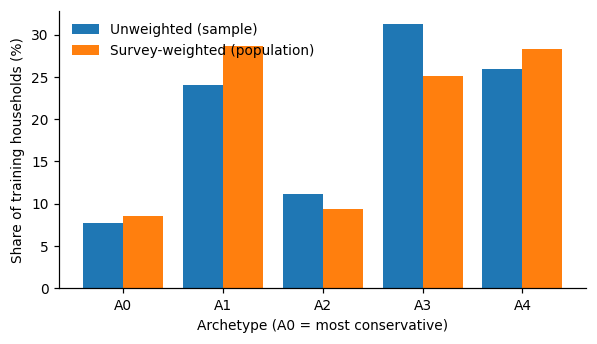

In [28]:
tr = feats["train"]
arche = sorted(tr["archetype"].unique())

# Figure 1: target balance
g = tr.groupby("archetype")
x = np.arange(len(arche))
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.bar(x - 0.2, g.size() / len(tr) * 100, 0.4, label="Unweighted (sample)")
ax.bar(x + 0.2, g["weight"].sum() / tr["weight"].sum() * 100, 0.4, label="Survey-weighted (population)")
ax.set_xticks(x, [f"A{a}" for a in arche])
ax.set_xlabel("Archetype (A0 = most conservative)")
ax.set_ylabel("Share of training households (%)")
ax.legend(frameon=False)
save_fig(fig, "fig01_target_balance")

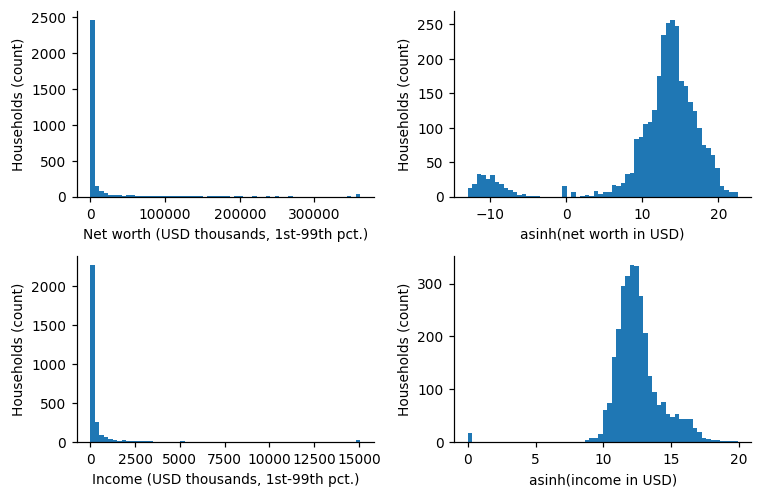

In [29]:
# Figure 2: skew before and after asinh
fig, axes = plt.subplots(2, 2, figsize=(7, 4.6))
for row, (c, lab) in enumerate([("networth", "Net worth"), ("income", "Income")]):
    lo, hi = tr[c].quantile([0.01, 0.99])
    axes[row, 0].hist(tr[c].clip(lo, hi) / 1e3, bins=60)
    axes[row, 0].set_xlabel(f"{lab} (USD thousands, 1st-99th pct.)")
    axes[row, 1].hist(np.arcsinh(tr[c]), bins=60)
    axes[row, 1].set_xlabel(f"asinh({lab.lower()} in USD)")
    for a in axes[row]:
        a.set_ylabel("Households (count)")
save_fig(fig, "fig02_skew_asinh")

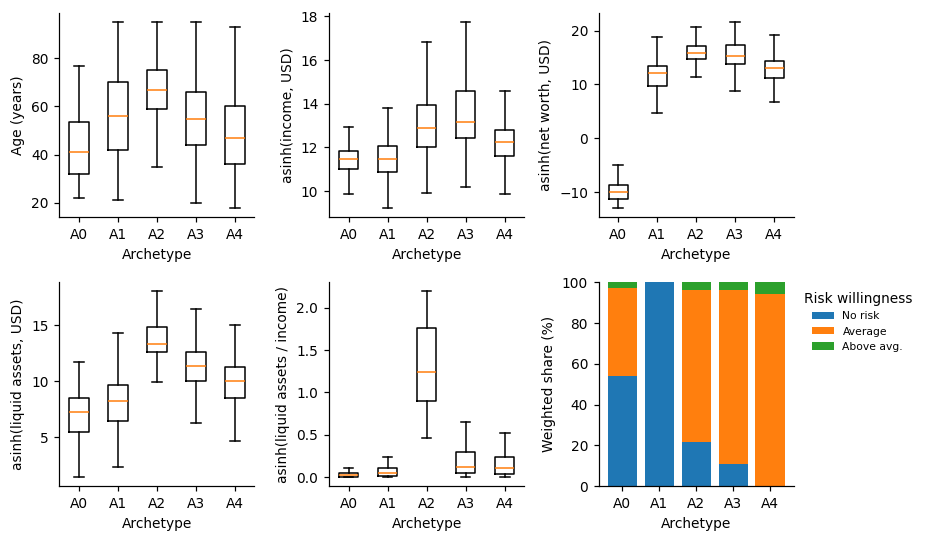

In [30]:
# Figure 3: intake features by archetype
panels = [("age", "Age (years)"), ("asinh_income", "asinh(income, USD)"),
          ("asinh_networth", "asinh(net worth, USD)"), ("asinh_liq", "asinh(liquid assets, USD)"),
          ("asinh_liq_to_income", "asinh(liquid assets / income)")]
fig, axes = plt.subplots(2, 3, figsize=(8.5, 5))
for ax, (c, lab) in zip(axes.flat, panels):
    ax.boxplot([tr.loc[tr["archetype"] == a, c] for a in arche], showfliers=False)
    ax.set_xticks(range(1, len(arche) + 1), [f"A{a}" for a in arche])
    ax.set_xlabel("Archetype")
    ax.set_ylabel(lab)
ax = axes.flat[-1]
ct = pd.crosstab(tr["archetype"], tr["risk_willingness"], values=tr["weight"],
                 aggfunc="sum", normalize="index") * 100
bottom = np.zeros(len(ct))
for r, name in zip(ct.columns, ["No risk", "Average", "Above avg."]):
    ax.bar([f"A{a}" for a in ct.index], ct[r], bottom=bottom, label=name)
    bottom += ct[r].to_numpy()
ax.set_xlabel("Archetype")
ax.set_ylabel("Weighted share (%)")
ax.legend(title="Risk willingness", frameon=False, fontsize=7, loc="upper left", bbox_to_anchor=(1, 1))
save_fig(fig, "fig03_features_by_archetype")

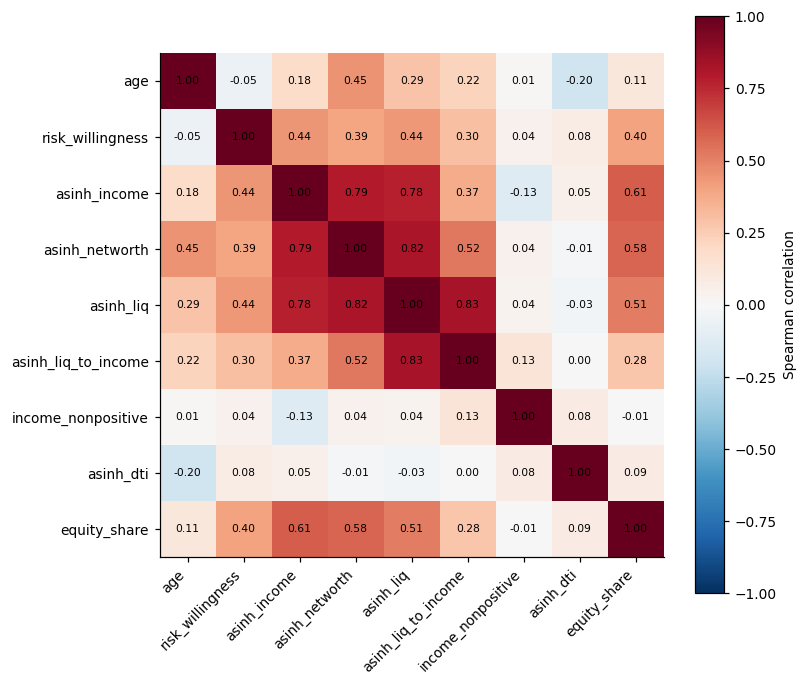

In [31]:
# Figure 4: correlations among features
def corr_plot(df, cols, name, method):
    c = df[cols].corr(method=method)
    fig, ax = plt.subplots(figsize=(0.6 * len(cols) + 2, 0.55 * len(cols) + 1.5))
    im = ax.imshow(c, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
    ax.set_yticks(range(len(cols)), cols)
    for i in range(len(cols)):
        for j in range(len(cols)):
            ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
    fig.colorbar(im, ax=ax, label=f"{method.capitalize()} correlation")
    save_fig(fig, name)
    return c

all_feats = list(dict.fromkeys(CLASSIFIER_FEATURES + CLUSTER_FEATURES))
scf_corr = corr_plot(tr, all_feats, "fig04_scf_corr", "spearman")
note("eda", "spearman", scf_corr.round(3).to_dict())

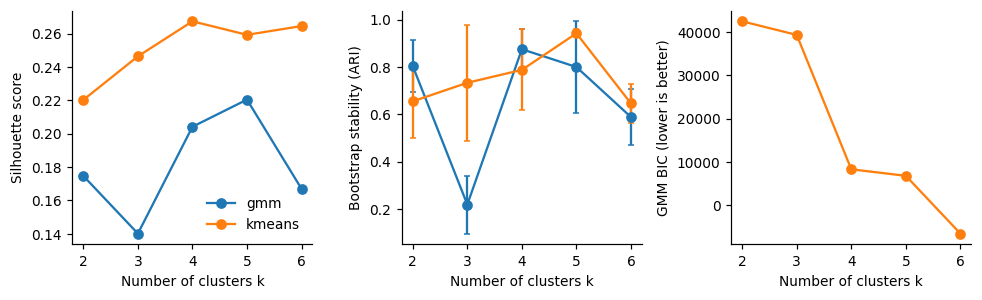

In [32]:
# Figure 5: choosing k
fig, axes = plt.subplots(1, 3, figsize=(9, 2.8))
for m, d in ktab.groupby("method"):
    axes[0].plot(d["k"], d["silhouette"], marker="o", label=m)
    axes[1].errorbar(d["k"], d["stability_ari_mean"], yerr=d["stability_ari_sd"], marker="o", capsize=2, label=m)
gm = ktab[ktab["method"] == "gmm"]
axes[2].plot(gm["k"], gm["bic"], marker="o", color="C1")
for a, lab in zip(axes, ["Silhouette score", "Bootstrap stability (ARI)", "GMM BIC (lower is better)"]):
    a.set_xlabel("Number of clusters k")
    a.set_ylabel(lab)
axes[0].legend(frameon=False)
save_fig(fig, "fig05_k_selection")

## Run PCA on the SCF clustering variables

In [33]:
Xp = weighted_resample(tr, SEED)[CLUSTER_FEATURES].to_numpy(float)
pca_scf = PCA(random_state=SEED).fit(StandardScaler().fit_transform(Xp))
evr_scf = pca_scf.explained_variance_ratio_
note("pca_scf", "explained", evr_scf.tolist())
note("pca_scf", "cumulative", np.cumsum(evr_scf).tolist())
note("pca_scf", "n_to_threshold", int(np.searchsorted(np.cumsum(evr_scf), PCA_THRESHOLD) + 1))
note("pca_scf", "n_eigen_gt_1", int((pca_scf.explained_variance_ > 1).sum()))
load_scf = pd.DataFrame(pca_scf.components_.T, index=CLUSTER_FEATURES,
                        columns=[f"PC{i+1}" for i in range(len(CLUSTER_FEATURES))])
load_scf.to_csv(TAB_DIR / "pca_scf_loadings.csv")
print("Cumulative variance:", np.cumsum(evr_scf).round(3))
load_scf.round(3)

Cumulative variance: [0.274 0.513 0.669 0.802 0.908 1.   ]


,PC1,PC2,PC3,PC4,PC5,PC6
age,0.302,0.570,0.346,-0.144,-0.345,0.569
risk_willingness,0.381,-0.492,-0.408,0.213,0.062,0.630
asinh_networth,0.579,0.097,0.202,-0.229,0.737,-0.139
asinh_dti,-0.026,-0.421,0.798,0.426,0.002,0.060
asinh_liq_to_income,0.493,0.262,-0.168,0.662,-0.246,-0.402
equity_share,0.430,-0.421,0.089,-0.512,-0.523,-0.307


## Step 14 - Load the ETF data and check its structure

In [37]:
from datetime import date

ETF_WIDE_FILE = Path("PortfolioPilot_ETF_Prices.csv")   # one column per ETF, next to the notebook

if not ETF_WIDE_FILE.exists():
    import yfinance as yf
    data = yf.download(tickers=TICKERS, start=ETF_START, end=ETF_END, interval="1d",
                       auto_adjust=True, progress=False)
    data["Close"].to_csv(ETF_WIDE_FILE)                # adjusted closing prices
    Path("etf_download_date.txt").write_text(str(date.today()))
    print("Downloaded on", date.today())
else:
    print("Using saved file:", ETF_WIDE_FILE)

wide = pd.read_csv(ETF_WIDE_FILE, index_col=0, parse_dates=True)
wide.index.name = "date"

# Structure checks
note("etf_raw", "rows_trading_days", len(wide))
note("etf_raw", "columns", wide.shape[1])
note("etf_raw", "date_range", [str(wide.index.min().date()), str(wide.index.max().date())])
note("etf_raw", "tickers_missing", sorted(set(TICKERS) - set(wide.columns)))
note("etf_raw", "unexpected_columns", sorted(set(wide.columns) - set(TICKERS)))
note("etf_raw", "missing_by_ticker", wide.isna().sum().to_dict())
note("etf_raw", "first_valid_date", {c: str(wide[c].first_valid_index().date()) for c in wide.columns})
if Path("etf_download_date.txt").exists():
    note("etf_raw", "download_date", Path("etf_download_date.txt").read_text())
assert len(wide) > 0, "No prices: the download failed. Delete the CSV and try again later."

# Long format (date, ticker, adj_close) used by Step 15
long = wide.reset_index().melt(id_vars="date", var_name="ticker", value_name="adj_close")
long.to_csv(ETF_FILE, index=False)

print(NUMBERS["etf_raw"])
wide.head()

Downloaded on 2026-10-23
{'rows_trading_days': 2514, 'columns': 9, 'date_range': ['2016-01-04', '2025-12-31'], 'tickers_missing': [], 'unexpected_columns': [], 'missing_by_ticker': {'AGG': 0, 'DBC': 0, 'GLD': 0, 'SPY': 0, 'TIP': 0, 'TLT': 0, 'VEA': 0, 'VNQ': 0, 'VWO': 0}, 'first_valid_date': {'AGG': '2016-01-04', 'DBC': '2016-01-04', 'GLD': '2016-01-04', 'SPY': '2016-01-04', 'TIP': '2016-01-04', 'TLT': '2016-01-04', 'VEA': '2016-01-04', 'VNQ': '2016-01-04', 'VWO': '2016-01-04'}, 'download_date': '2026-10-23'}


,AGG,DBC,GLD,SPY,TIP,TLT,VEA,VNQ,VWO
date,,,,,,,,,
2016-01-04,79.657753,11.210503,102.889999,169.051773,80.085342,89.580688,26.352303,51.486614,23.626696
2016-01-05,79.694633,11.100595,103.180000,169.337692,80.034424,89.219238,26.323160,52.480160,23.678740
2016-01-06,79.997086,10.923054,104.669998,167.201645,80.288979,90.421509,25.842299,52.336346,23.254967
2016-01-07,79.989677,10.872327,106.150002,163.190186,80.223503,90.583824,25.354160,51.316669,22.504093
2016-01-08,80.166809,10.821601,105.680000,161.398956,80.288979,90.989456,25.040878,50.630371,22.303368


## Step 15 - Clean ETF prices, compute returns, split by time

In [40]:
# ---- Load the long-format ETF prices saved in Step 14 (one row per date and ticker) ----
eraw = pd.read_csv(ETF_FILE, parse_dates=["date"])

# ---- Data-quality checks (counts go into Table 1 of the report) ----
note("etf", "rows", len(eraw))                                                   # total rows loaded
note("etf", "tickers_missing", sorted(set(TICKERS) - set(eraw["ticker"])))       # expected ETFs not in the file
note("etf", "duplicate_date_ticker", int(eraw.duplicated(["date", "ticker"]).sum()))  # same ETF twice on one day
note("etf", "missing_prices", int(eraw["adj_close"].isna().sum()))               # blank prices
note("etf", "non_positive_prices", int((eraw["adj_close"] <= 0).sum()))          # impossible prices (0 or negative)

# ---- Fix problems found above ----
eraw = eraw.drop_duplicates(["date", "ticker"], keep="last")   # keep one row per ETF per day
eraw = eraw[eraw["adj_close"] > 0]                             # drop impossible prices

# Reshape to wide format: one row per trading day, one column per ETF, in the order of TICKERS
prices = eraw.pivot(index="date", columns="ticker", values="adj_close").sort_index()[TICKERS]

# Count trading days where an ETF has no price
gaps = prices.isna().sum()
note("etf", "missing_days_by_ticker", gaps[gaps > 0].to_dict())

# Fill isolated one-day gaps with the previous day's price (= zero return that day);
# longer gaps are left empty and those days are dropped below
filled = prices.ffill(limit=1)
note("etf", "cells_forward_filled", int(prices.isna().sum().sum() - filled.isna().sum().sum()))
prices = filled.dropna()                                       # keep only days with all 9 prices

note("etf", "trading_days", len(prices))
note("etf", "date_range", [str(prices.index.min().date()), str(prices.index.max().date())])

# ---- Daily log returns: log(today's price / yesterday's price) ----
ret = np.log(prices).diff().dropna()                           # first day has no previous price, so it is dropped

# ---- Time-based split (no shuffling: the future must never inform the past) ----
# train: 2016 to 2021 | validation: 2022 to 2023 | test: 2024 to 2025
t_end, v_end = pd.Timestamp(ETF_TRAIN_END), pd.Timestamp(ETF_VAL_END)
etf_parts = {"train": ret.loc[:t_end],
             "val":   ret.loc[t_end + pd.Timedelta(days=1): v_end],
             "test":  ret.loc[v_end + pd.Timedelta(days=1):]}

# Save each period for M4 and record its size and date range (Table 2 of the report)
for name, d in etf_parts.items():
    d.to_csv(DATA_DIR / f"etf_returns_{name}.csv")
    note("etf_split", name, {"days": len(d), "from": str(d.index.min().date()), "to": str(d.index.max().date())})

# Show the cleaning counts and the split summary
NUMBERS["etf"], NUMBERS["etf_split"]

({'rows': 22626,
  'tickers_missing': [],
  'duplicate_date_ticker': 0,
  'missing_prices': 0,
  'non_positive_prices': 0,
  'missing_days_by_ticker': {},
  'cells_forward_filled': 0,
  'trading_days': 2514,
  'date_range': ['2016-01-04', '2025-12-31']},
 {'train': {'days': 1510, 'from': '2016-01-05', 'to': '2021-12-31'},
  'val': {'days': 501, 'from': '2022-01-03', 'to': '2023-12-29'},
  'test': {'days': 502, 'from': '2024-01-02', 'to': '2025-12-31'}})

## Step 16 - ETF exploration (training period only)

Extreme-return dates: ['2016-06-24', '2016-11-09', '2020-03-06', '2020-03-09', '2020-03-10', '2020-03-11', '2020-03-12', '2020-03-13', '2020-03-16', '2020-03-17', '2020-03-18', '2020-03-19', '2020-03-20', '2020-03-23', '2020-03-24', '2020-03-30', '2020-04-06', '2020-06-11', '2020-08-11', '2020-11-09', '2021-11-26']


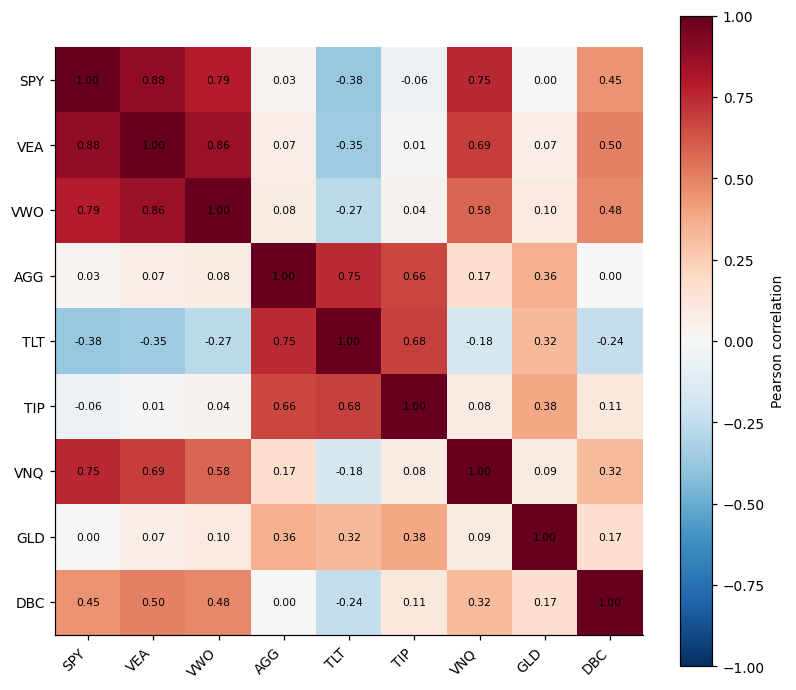

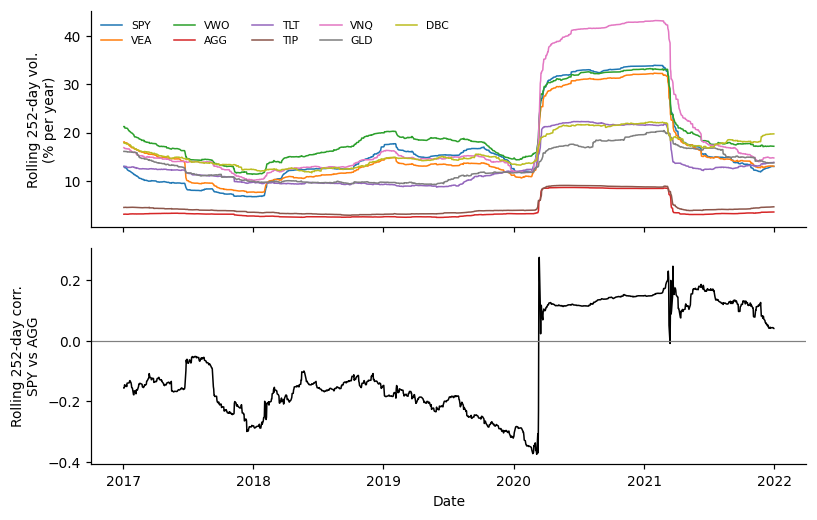

In [41]:
etr = etf_parts["train"]

z = (etr - etr.mean()) / etr.std()
flags = z.abs() > 5
note("etf_outliers", "n_flagged_by_ticker", flags.sum().to_dict())
note("etf_outliers", "dates", [str(d.date()) for d in etr.index[flags.any(axis=1)]])
note("etf_eda", "annual_vol_train", (etr.std() * np.sqrt(252)).to_dict())
print("Extreme-return dates:", NUMBERS["etf_outliers"]["dates"])

etf_corr = corr_plot(etr, TICKERS, "fig06_etf_corr", "pearson")
note("etf_eda", "corr_train", etf_corr.round(3).to_dict())

fig, axes = plt.subplots(2, 1, figsize=(7.5, 4.8), sharex=True)
vol = etr.rolling(252).std() * np.sqrt(252) * 100
for c in TICKERS:
    axes[0].plot(vol.index, vol[c], lw=1, label=c)
axes[0].set_ylabel("Rolling 252-day vol.\n(% per year)")
axes[0].legend(ncol=5, frameon=False, fontsize=7)
axes[1].plot(etr.index, etr["SPY"].rolling(252).corr(etr["AGG"]), color="k", lw=1)
axes[1].axhline(0, color="grey", lw=0.8)
axes[1].set_ylabel("Rolling 252-day corr.\nSPY vs AGG")
axes[1].set_xlabel("Date")
save_fig(fig, "fig07_etf_rolling")

# Inspect extreme ETF returns (training period)
List every daily return beyond 5 training standard deviations, with its date, ETF and size, to check whether each is a real market event or a data error.

In [43]:
z = (etr - etr.mean()) / etr.std()
flagged = (etr[z.abs() > 5].stack().rename("log_return").to_frame()
           .assign(z=z.stack(), pct_return=lambda d: (np.exp(d["log_return"]) - 1) * 100)
           .round(2))
flagged.index.names = ["date", "ticker"]
flagged.sort_index()

log_return      z  pct_return
date       ticker                               
2016-06-24 GLD           0.05   5.43        4.90
           VEA          -0.09  -7.63       -8.19
2016-11-09 TLT          -0.04  -5.01       -4.24
2020-03-06 TLT           0.05   5.81        5.20
2020-03-09 DBC          -0.08  -7.59       -7.78
           SPY          -0.08  -7.19       -7.81
           TIP          -0.02  -6.52       -2.06
           VEA          -0.08  -7.57       -8.13
           VNQ          -0.08  -5.88       -7.71
           VWO          -0.08  -5.96       -7.45
2020-03-10 TIP          -0.03  -9.10       -2.87
           TLT          -0.05  -6.07       -5.13
2020-03-11 AGG          -0.01  -5.18       -1.43
           TIP          -0.02  -7.18       -2.26
2020-03-12 AGG          -0.04 -14.63       -4.00
           SPY          -0.10  -8.88       -9.57
           VEA          -0.12 -10.57      -11.18
           VNQ          -0.11  -7.81      -10.13
           VWO          -0.11  -8.14      -10.05
2020-03-13 AGG           0.02   5.52        1.57
           SPY           0.08   7.14        8.55
           VEA           0.06   5.41        6.31
           VNQ           0.08   6.07        8.73
           VWO           0.07   5.15        7.00
2020-03-16 AGG           0.02   5.88        1.67
           DBC          -0.06  -5.83       -6.03
           SPY          -0.12 -10.22      -10.94
           TLT           0.06   7.19        6.48
           VEA          -0.11 -10.21      -10.82
           VNQ          -0.20 -14.25      -17.73
           VWO          -0.13  -9.90      -12.09
2020-03-17 AGG          -0.03  -9.40       -2.59
           TIP          -0.03  -8.88       -2.80
           TLT          -0.07  -7.96       -6.67
2020-03-18 AGG          -0.04 -13.92       -3.81
           TLT          -0.06  -6.70       -5.64
           VEA          -0.06  -5.48       -5.95
           VNQ          -0.10  -7.31       -9.51
           VWO          -0.08  -6.53       -8.14
2020-03-19 AGG           0.02   7.84        2.23
           TIP           0.02   5.91        1.94
2020-03-20 TIP           0.04  13.48        4.45
           TLT           0.07   8.31        7.52
2020-03-23 AGG           0.02   8.33        2.37
           TIP           0.02   5.73        1.88
2020-03-24 GLD           0.05   5.38        4.85
           SPY           0.09   7.55        9.06
           VEA           0.09   7.54        8.90
           VNQ           0.09   6.25        9.00
2020-03-30 TIP          -0.02  -5.04       -1.59
2020-04-06 SPY           0.07   5.64        6.72
           VNQ           0.07   5.18        7.41
2020-06-11 SPY          -0.06  -5.26       -5.76
           VEA          -0.06  -5.05       -5.49
2020-08-11 GLD          -0.06  -6.35       -5.37
2020-11-09 GLD          -0.05  -5.21       -4.43
2021-11-26 DBC          -0.06  -5.77       -5.96

## PCA on ETF returns and the scree plot

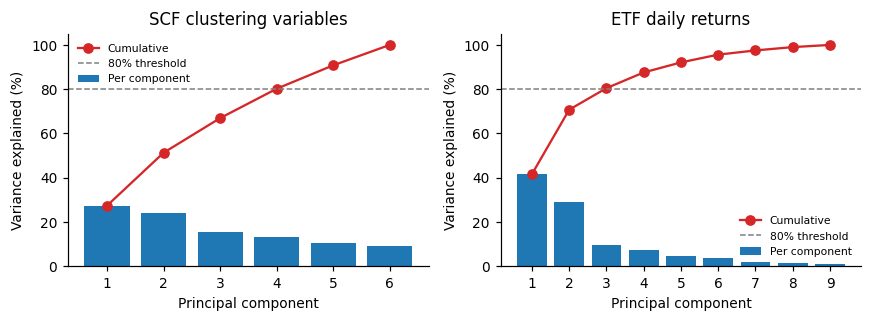

ETF cumulative variance: [0.416 0.707 0.805 0.876 0.921 0.956 0.975 0.99  1.   ]


,PC1,PC2,PC3
SPY,0.483,0.013,-0.179
VEA,0.489,0.053,-0.079
VWO,0.456,0.076,-0.019
AGG,-0.014,0.549,-0.256
TLT,-0.237,0.501,-0.178
TIP,-0.037,0.535,0.004
VNQ,0.403,0.119,-0.303
GLD,0.027,0.367,0.628
DBC,0.315,0.067,0.614


In [42]:
pca_etf = PCA(random_state=SEED).fit(StandardScaler().fit_transform(etr))
evr_etf = pca_etf.explained_variance_ratio_
note("pca_etf", "explained", evr_etf.tolist())
note("pca_etf", "cumulative", np.cumsum(evr_etf).tolist())
note("pca_etf", "n_to_threshold", int(np.searchsorted(np.cumsum(evr_etf), PCA_THRESHOLD) + 1))
load_etf = pd.DataFrame(pca_etf.components_.T, index=TICKERS, columns=[f"PC{i+1}" for i in range(9)])
load_etf.to_csv(TAB_DIR / "pca_etf_loadings.csv")

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, (title, evr) in zip(axes, [("SCF clustering variables", evr_scf), ("ETF daily returns", evr_etf)]):
    xs = np.arange(1, len(evr) + 1)
    ax.bar(xs, evr * 100, label="Per component")
    ax.plot(xs, np.cumsum(evr) * 100, marker="o", color="C3", label="Cumulative")
    ax.axhline(PCA_THRESHOLD * 100, ls="--", color="grey", lw=1, label=f"{int(PCA_THRESHOLD*100)}% threshold")
    ax.set_xticks(xs)
    ax.set_xlabel("Principal component")
    ax.set_ylabel("Variance explained (%)")
    ax.set_title(title)
    ax.legend(frameon=False, fontsize=7)
save_fig(fig, "fig08_pca_scree")
print("ETF cumulative variance:", np.cumsum(evr_etf).round(3))
load_etf.iloc[:, :3].round(3)